In [4]:
import sys
sys.path.insert(0, '/home/nvidia/24BCE1793/fignn_cni__project')  # on A100

from src.preprocessing.preprocess import process_file
from src.preprocessing.plv import batch_compute_plv
from src.preprocessing.graph_builder import build_graph_dataset

from src.models.model import FIGNNEncoder, count_parameters
from torch_geometric.loader import DataLoader
import torch

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geom

In [5]:
print(os.getcwd())

/home/nvidia/24BCE1793/fignn_cni__project/notebooks


In [4]:
result = process_file(
    "lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set",
    label=0
)
print(f"Epochs:   {result['n_epochs']}")
print(f"Channels: {result['n_channels']}")
print(f"Theta shape: {result['band_epochs']['theta'].shape}")

  Loading: zeroBACK.set  label=0


d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, prel

    → 62 channels  |  198 epochs  |  500.0 Hz
Epochs:   198
Channels: 62
Theta shape: (198, 62, 1000)


In [5]:
# Slice just 3 epochs to test PLV fast
test_bands = {band: result['band_epochs'][band][:3] 
              for band in result['band_epochs']}
test_result = {**result, 'band_epochs': test_bands, 'n_epochs': 3}

plv_list = batch_compute_plv(test_result['band_epochs'])
print(f"PLV list length: {len(plv_list)}")
print(f"PLV matrix shape (delta): {plv_list[0]['delta'].shape}")

    PLV: epoch 0/3
PLV list length: 3
PLV matrix shape (delta): (62, 62)


In [6]:
graphs = build_graph_dataset(test_result, plv_list)
g = graphs[0]
print(f"Nodes: {g.x.shape}")
print(f"Edges: {g.edge_index.shape}")
print(f"Edge features: {g.edge_attr.shape}")
print(f"Label: {g.y}")

    Built 3 graphs  |  sample edges: 2422  |  label: 0
Nodes: torch.Size([62, 4])
Edges: torch.Size([2, 2422])
Edge features: torch.Size([2422, 4])
Label: tensor([0])


In [9]:
model = FIGNNEncoder()
count_parameters(model)

# Make a small batch from your 3 test graphs
loader = DataLoader(graphs, batch_size=3)
batch  = next(iter(loader))

# Forward pass — no training, just checking shapes
model.eval()
with torch.no_grad():
    z = model(batch)

print(f"Output z shape: {z.shape}")
print(f"Expected: torch.Size([3, 32])")

Trainable parameters: 12,100
Output z shape: torch.Size([3, 32])
Expected: torch.Size([3, 32])


In [ ]:
import mne
mne.set_log_level("WARNING")
raw_tmp = mne.io.read_raw_eeglab(
    "../data/raw/sub-01/ses-S1/eeg/zeroBACK.set", 
    preload=False, verbose=False
)
ecg_chs = [ch for ch in raw_tmp.ch_names if "ECG" in ch.upper()]
raw_tmp.drop_channels(ecg_chs)
ch_names = raw_tmp.ch_names  # exactly 62 names

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.utils import to_networkx
import numpy as np

g = graphs[0]

# Convert to networkx
G = to_networkx(g, to_undirected=True)

# Node positions — use actual electrode layout (approximate)
# For now just use spring layout
pos = nx.spring_layout(G, seed=42)

# Node colours = theta band power (index 1)
node_colors = g.x[:, 1].numpy()  # theta power per electrode

# Edge weights = mean PLV across 4 bands
edge_weights = g.edge_attr.mean(dim=1).numpy()

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor("#0d0d1a")
fig.patch.set_facecolor("#0d0d1a")

# Draw edges
nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color=edge_weights[:len(G.edges())],
    edge_cmap=plt.cm.plasma,
    alpha=0.3, width=0.5)

# Draw nodes
nc = nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=node_colors,
    cmap=plt.cm.RdYlGn,
    node_size=120)

# Labels
nx.draw_networkx_labels(G, pos, ax=ax,
    labels={i: ch_names[i] for i in range(len(ch_names))},
    font_size=5, font_color="white")

plt.colorbar(nc, ax=ax, label="Theta power", shrink=0.6)
ax.set_title("EEG Functional Connectivity Graph — zeroBACK epoch 0", 
             color="white", fontsize=11)
ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/plots/graph_viz.png", dpi=150, bbox_inches="tight")
plt.close()
print("Saved to outputs/plots/graph_viz.png")

KeyError: 62

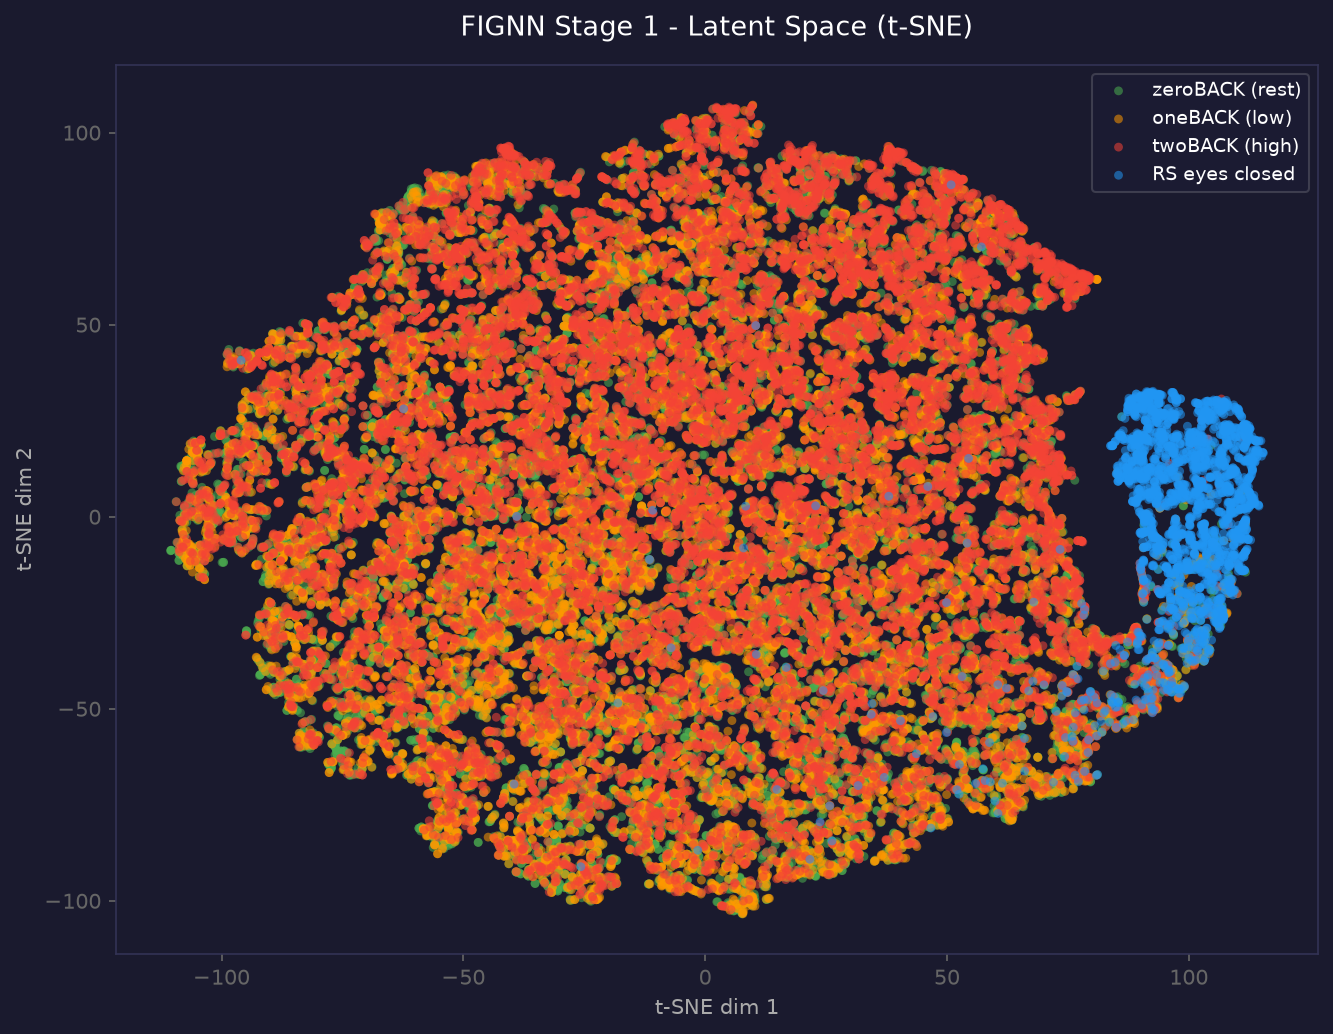

In [15]:
from IPython.display import Image, display
display(Image('/lp-dev/24BCE1793/outputs/plots/tsne_latent_space.png'))
# display(Image('/lp-dev/24BCE1793/outputs/plots/band_importance.png'))
# display(Image('/lp-dev/24BCE1793/outputs/plots/loss_curve.png'))

In [13]:
import pickle, torch

# Run this right now before you forget
from ...src.training.train import compute_dataset_stats
import pickle

with open('/lp-dev/24BCE1793/data/processed/all_graphs_29sub.pkl', 'rb') as f:
    graphs = pickle.load(f)

mean, std = compute_dataset_stats(graphs)
torch.save({'mean': mean, 'std': std}, 
           '/lp-dev/24BCE1793/outputs/checkpoints/normalisation_stats.pt')
print("Saved normalisation stats")

ImportError: attempted relative import with no known parent package

In [7]:
import mne
import os
import json
import scipy.io as sio
import numpy as np

mne.set_log_level('ERROR')

DATA_ROOT = "/lp-dev/24BCE1793/data/raw"

# ── 1. Check one subject from each group ─────────────────────────────
print("=" * 60)
print("CHANNEL STRUCTURE COMPARISON")
print("=" * 60)

for sub in ['sub-01', 'sub-10']:
    path = os.path.join(DATA_ROOT, sub, 'ses-S1', 'eeg', 'zeroBACK.set')
    raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
    ecg  = [c for c in raw.ch_names if 'ECG' in c.upper()]
    print(f"\n{sub}:")
    print(f"  Total channels : {len(raw.ch_names)}")
    print(f"  ECG channels   : {ecg}")
    print(f"  Has Cz         : {'Cz' in raw.ch_names}")
    print(f"  Sampling rate  : {raw.info['sfreq']} Hz")
    print(f"  Duration       : {raw.times[-1]:.1f}s")
    print(f"  Channel names  : {raw.ch_names}")

# ── 2. Check all 3 sessions for one subject ───────────────────────────
print("\n" + "=" * 60)
print("SESSION CONSISTENCY — sub-01")
print("=" * 60)

for ses in ['ses-S1', 'ses-S2', 'ses-S3']:
    for task in ['zeroBACK', 'oneBACK', 'twoBACK']:
        path = os.path.join(DATA_ROOT, 'sub-01', ses, 'eeg', f'{task}.set')
        raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
        print(f"  {ses} {task}: {len(raw.ch_names)} ch  {raw.times[-1]:.1f}s  {len(raw.annotations)} annotations")

# ── 3. Look at annotation/event codes ────────────────────────────────
print("\n" + "=" * 60)
print("EVENT CODES — sub-01 ses-S1 zeroBACK")
print("=" * 60)

path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'eeg', 'zeroBACK.set')
raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
from collections import Counter
event_counts = Counter(raw.annotations.description)
for event, count in sorted(event_counts.items()):
    print(f"  {event:15s}: {count} occurrences")

# ── 4. Look at behavioral data ────────────────────────────────────────
print("\n" + "=" * 60)
print("BEHAVIORAL DATA — sub-01 ses-S1 0-Back")
print("=" * 60)

mat_path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'behavioral', '0-Back.mat')
try:
    mat = sio.loadmat(mat_path)
    print(f"  Keys: {[k for k in mat.keys() if not k.startswith('_')]}")
    for k, v in mat.items():
        if not k.startswith('_'):
            print(f"  {k}: shape={np.array(v).shape}  dtype={np.array(v).dtype}")
except Exception as e:
    print(f"  Error: {e}")

# ── 5. Check chanlocs file ────────────────────────────────────────────
print("\n" + "=" * 60)
print("CHANLOCS — sub-01 ses-S1")
print("=" * 60)

chanlocs_path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'chanlocs', 'get_chanlocs.txt')
with open(chanlocs_path) as f:
    content = f.read()
print(content[:500])

# ── 6. Cross-subject duration check ──────────────────────────────────
print("\n" + "=" * 60)
print("DURATION CONSISTENCY ACROSS SUBJECTS — zeroBACK ses-S1")
print("=" * 60)

for sub_n in range(1, 30):
    sub  = f"sub-{sub_n:02d}"
    path = os.path.join(DATA_ROOT, sub, 'ses-S1', 'eeg', 'zeroBACK.set')
    if not os.path.exists(path):
        print(f"  {sub}: FILE NOT FOUND")
        continue
    raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
    ecg = [c for c in raw.ch_names if 'ECG' in c.upper()]
    n_eeg = len(raw.ch_names) - len(ecg)
    print(f"  {sub}: {n_eeg} EEG  {raw.times[-1]:.1f}s  {raw.info['sfreq']}Hz")

CHANNEL STRUCTURE COMPARISON


/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=


sub-01:
  Total channels : 63
  ECG channels   : ['ECG1']
  Has Cz         : False
  Sampling rate  : 500.0 Hz
  Duration       : 396.6s
  Channel names  : ['Fp1', 'Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'ECG1', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'FCz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'C1', 'C5', 'TP7', 'CP3', 'P1', 'P5', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'P6', 'P2', 'CPz', 'CP4', 'TP8', 'C6', 'C2', 'FC4', 'FT8', 'F6', 'AF8', 'AF4', 'F2']

sub-10:
  Total channels : 64
  ECG channels   : ['ECG1']
  Has Cz         : True
  Sampling rate  : 500.0 Hz
  Duration       : 344.9s
  Channel names  : ['Fp1', 'Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'ECG1', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'FCz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'C1', 'C5', '

/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=

  ses-S1 zeroBACK: 63 ch  396.6s  203 annotations
  ses-S1 oneBACK: 63 ch  411.3s  198 annotations


...

/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=Fals

  sub-25: 63 EEG  331.9s  500.0Hz
  sub-26: 63 EEG  328.7s  500.0Hz


/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=Fals

  sub-27: 63 EEG  328.3s  500.0Hz
  sub-28: 63 EEG  331.9s  500.0Hz
  sub-29: 63 EEG  321.9s  500.0Hz


/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)


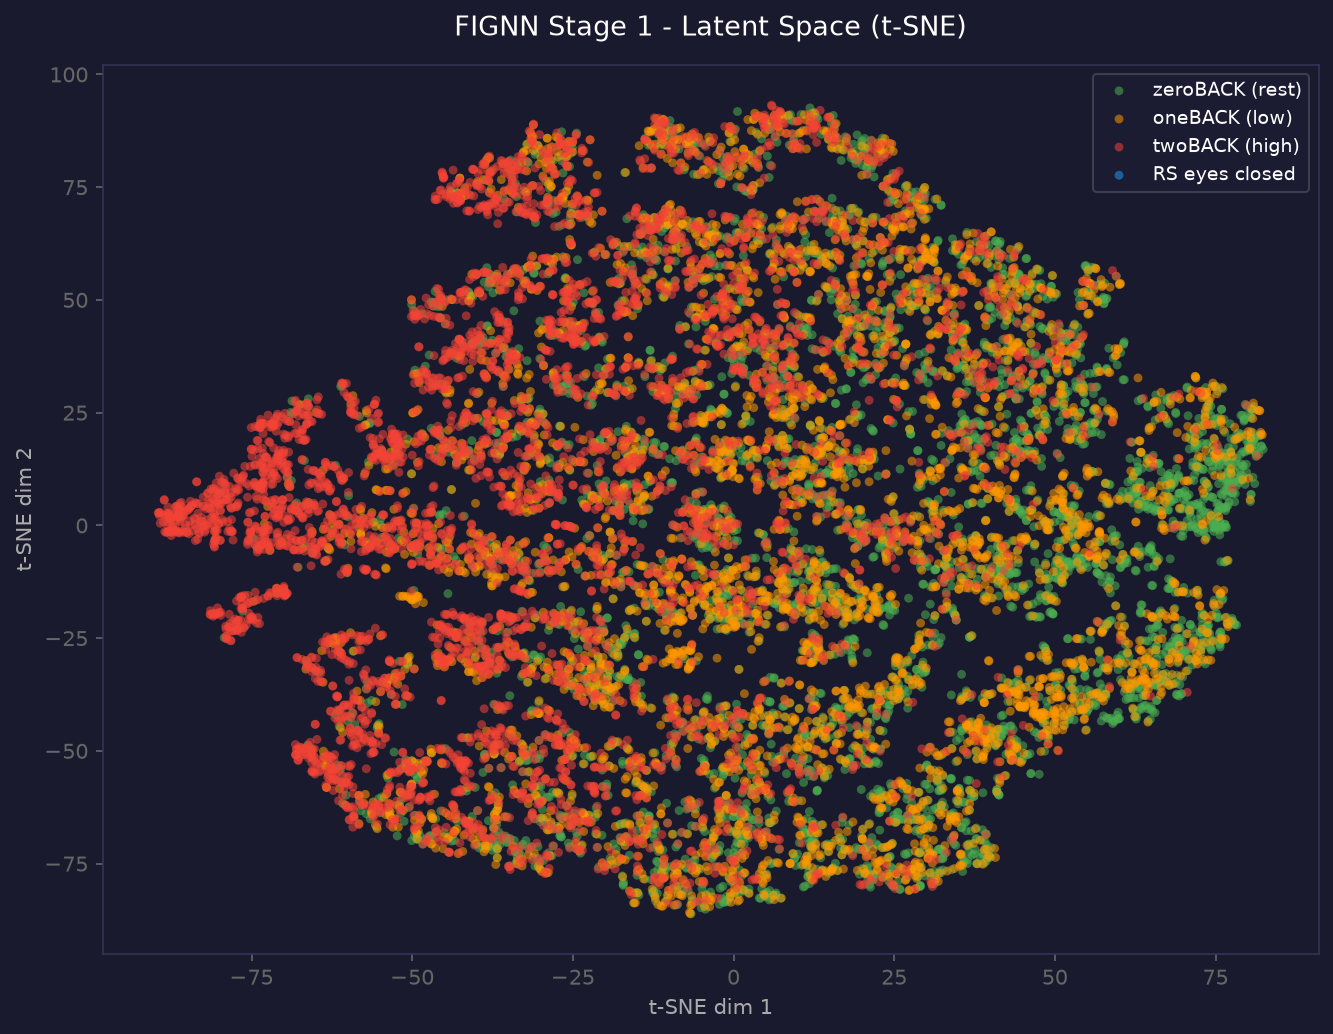

In [9]:
from IPython.display import Image
Image('/lp-dev/24BCE1793/outputs/plots/tsne_latent_space.png')